## Miniproject #1: Oligo T<sub>m</sub> calculator with flexible user interface
**Basic project aim: Compare empirical and nearest neighbor methods for T<sub>m</sub> estimation**
<div style="border:2px solid #ccc; padding:10px; border-radius:8px; background:#f9f9f9;">
<b>Input:</b> user provides text file with list of primer names and sequences <br>
<b>Output:</b> empirical versus nearest neighbor method T<sub>m</sub> estimates for all primers
</div>  

- Advanced option1: Predict hairpins, homodimers and heterodimers
- Advanced option2: Manage PCR primer pair designs on DNA target regions
- Advanced option3: Support primer design for real time qPCR applications
- Advanced option4: Propose your own flexible user interface improvements...

**Summary table methods for oligonucleotide T<sub>m</sub> estimation:**

| Feature           | Wallace rule*      | Empirical methods     | NN thermodynamics            |
| ----------------- | ------------------ | --------------------  | ---------------------------- |
| Model basis       |  GC count          | GC%, length, other factors  | + Dinucleotide stacking        |
| Context awareness |  none              | none                  | strong                       |
| Accuracy          |  ±5–10°C           | ±2–5°C                | ±1–2°C                       |
| Used for          |  not useful        | quick estimates       | Primer design, qPCR, cloning |
| Sequence detail   |  weak              | weak                  | high                         |

_*Wallace rule: T<sub>m</sub> ≈ 2 count(A:T) + 4 × count(G:C)_

<div style="border:2px solid #ccc; padding:10px; border-radius:8px; background:#f9f9f9;">
<b>Empirical method</b> based on von Ahsen et al. (2001) with 0.050 M Na<sup>+</sup>
$$
T_m = 77.1 \;+\; 0.41\,{GC} \;-\; \frac{528}{L} \;+\; 11.7\,\log_{10}(50\times10^{-3})
$$
<i>L</i> = oligonucleotide length<br>
<i>GC</i> = percentage of G or C nucleotides (%GC)
</div>

<div style="border:1px solid #dddddd; border-radius:8px; padding:12px 18px; background-color:#f7f7f7;">
<b>Background for the Nearest-neighbor method (Thermodynamics) </b>

Gibbs free energy is defined as:

$$
\Delta G^\circ(T) = \Delta H^\circ - T\,\Delta S^\circ
$$

At the melting temperature T<sub>m</sub>, the duplex is half-denatured, meaning:

$$
\Delta G^\circ(T_m) = 0
$$

Therefore:

$$
0 = \Delta H^\circ - T_m\,\Delta S^\circ
$$

Solve for T<sub>m</sub>:

$$
T_m = \frac{\Delta H^\circ}{\Delta S^\circ}
$$
</div>

<div style="border:1px solid #dddddd; border-radius:8px; padding:12px 18px; background-color:#f7f7f7;">
<b>Nearest-neighbor method</b> from SantaLucia (1998); SantaLucia & Hicks (2004)
    
$$
T_m = \frac{\sum \Delta H^\circ_{\text{NN}} + \Delta H^\circ_{\text{init}}}{\sum \Delta S^\circ_{\text{NN}} + \Delta S^\circ_{\text{init}} + R \ln\!\left(\frac{C}{4}\right)} - 273.15
$$

*C* = total strand concentration  
$\Delta H^\circ_{\text{NN}}$ = enthalpy of dinucleotide stacking steps  
$\Delta S^\circ_{\text{NN}}$ = entropy of dinucleotide stacking steps  
$R$ = 1.987 cal·K⁻¹·mol⁻¹ (gas constant)

<div style="text-align:center;">Biopython <b>DNA_NN4</b>: SantaLucia & Hicks 2004 table</div>

| Stack | ΔH° (kcal/mol) | ΔS° (cal/mol·K) | ΔG°₃₇ (kcal/mol) |
| ----- | -------------- | --------------- | ---------------- |
| AA/TT | −7.6           | −21.3           | −1.00            |
| AT/TA | −7.2           | −20.4           | −0.88            |
| TA/AT | −7.2           | −21.3           | −0.58            |
| CA/GT | −8.5           | −22.7           | −1.45            |
| GT/CA | −8.4           | −22.4           | −1.44            |
| CT/GA | −7.8           | −21.0           | −1.28            |
| GA/CT | −8.2           | −22.2           | −1.30            |
| CG/GC | −10.6          | −27.2           | −2.17            |
| GC/CG | −9.8           | −24.4           | −2.24            |
| GG/CC | −8.0           | −19.9           | −1.84            |

| Parameter                | ΔH° (kcal/mol) | ΔS° (cal/mol·K) | Notes |
|--------------------------|----------------|------------------|-------|
| Initiation               | +0.2           | −5.7             | General helix initiation term |
| Terminal A·T penalty     | +2.2           | +6.9             | Applied for each terminal A·T base pair |
| Terminal G·C adjustment  | 0.0            | 0.0              | No additional penalty or bonus |
| Symmetry correction      | 0.0            | −1.4             | Applied if sequence is self-complementary |

</div>

**Biopython library**
for DNA/DNA hybridizations implements four possible NN tables:
- DNA_NN1: Breslauer et al. 1986
- DNA_NN2: Sugimoto et al. 1996
- DNA_NN3: Allawi & SantaLucia 1997 (**Default**)
- DNA_NN4: SantaLucia & Hicks 2004

In [37]:
# Different Nearest-Neighbor tables are available in Biopython
from Bio.SeqUtils import MeltingTemp as mt
from Bio.Seq import Seq

seq = Seq("GTCAGAGATCACTAAGAGGCTTATCAAAGC")

print(mt.Tm_NN(seq))                       # <- uses DNA_NN3 (Default)
print(mt.Tm_NN(seq, nn_table=mt.DNA_NN4))  # <- uses DNA_NN4 (SantaLucia & Hicks 2004)

57.34375229056457
57.28230655435436


## Oligonucleotide melting temperature (T<sub>m</sub>) estimation

#### How should you input primer sequences into your program?

In [38]:
# Data can be provided hardcoded as a list in the code
# Not flexible, no oligo names, user input impossible

In [39]:
import re, math, sys

# hardcoded list with oligo sequences
seqs = ["TAATGCGGGAGAGGATCAAGG",
        "AGTAGAAGAACCGCAGCTGAATC",
        "AACCCAAAGGTTGGATGGTTCCAGG",
        "AAGATATATCGGATTCCCATCCGAAAGTGG",
        "TGTCTATCGACTACAGAGAGATTTTGCATTGC",
        "TGCGGCAAATACACCCCAATGG",
        "GTCAGAGATCACTAAGAGGCTTATCAAAGC",
        "TAGTTTCAGGAATGCACTTCTAAGGACATCC",
        "GGCTGCACAGCTGATGATTACAA",
        "GCCGCTCGAGATCATCAGCAAAGGAAT",
        "TGTTCATTCAGTTACAAGTCGTG",
        "TTCACCTTTTTGATCCCTTGATC",
        "ATGGTGTCAGAGACGACGACG",
        "CAGAAGCGTCACCATTAACACAAC",
        "CTGATCGCGAGATTTCAGTTC",
        "AGAAGATTGGAGCAAGCTTCC",
        "GCTGGAAGGGAAAGCTTAACAACC",
        "ACACTGCCATCGATTCTGCAAACC",
        "CATTATGATCGA",
        "CATTATGATCGATTTAGGTTAC",
        "CATTATGATCGATTTAGGTTACTGACTCTATT",
        "CATTATGATCGATTTAGGTTACTGACTCTATTCATATCTTGA",
        "GGCTAGGCATGG",
        "GGCTAGGCATGGCTCGTCCAGC",
        "GGCTAGGCATGGCTCGTCCAGCTTCGCTGCTG",
        "GGCTAGGCATGGCTCGTCCAGCTTCGCTGCTGGCTGTCAGCA",
        "ATATATATATAT",
        "ATATATATATATATATATATAT",
        "ATATATATATATATATATATATATATATATAT",
        "ATATATATATATATATATATATATATATATATATATATATAT",
        "GCGCGCGCGCGC",
        "GCGCGCGCGCGCGCGCGCGCGC",
        "GCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGC",
        "GCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGC"
]

print(f"{'Sequence (<=45 nt)':45}  {'Len':>3}  {'GC%':>5}  {'Tm(50mM)':>7}")

# Loop through one or more input sequences
for raw in seqs:
    s = re.sub(r'[^ACGTacgt]','',raw).upper() # Check and clean-up input
    if s == '':
        print("# skipped line (no A/C/G/T found)", file = sys.stderr)
    else:
        L = len(s)
        gc = 100 * sum(b in 'GC' for b in s)/L
        tm = 77.1 + 0.41*gc - 528/L + 11.7*math.log10(50e-3)   # Salt-adjusted GC% formula   
        disp = (s[:45] + '...') if L > 45 else s               # Show up to 45 nt of oligo
        print(f"{disp:45}  {L:3d}  {gc:5.1f}  {tm:7.1f}")      # print input seq and result

Sequence (<=45 nt)                             Len    GC%  Tm(50mM)
TAATGCGGGAGAGGATCAAGG                           21   52.4     58.2
AGTAGAAGAACCGCAGCTGAATC                         23   47.8     58.5
AACCCAAAGGTTGGATGGTTCCAGG                       25   52.0     62.1
AAGATATATCGGATTCCCATCCGAAAGTGG                  30   43.3     62.0
TGTCTATCGACTACAGAGAGATTTTGCATTGC                32   40.6     62.0
TGCGGCAAATACACCCCAATGG                          22   54.5     60.2
GTCAGAGATCACTAAGAGGCTTATCAAAGC                  30   43.3     62.0
TAGTTTCAGGAATGCACTTCTAAGGACATCC                 31   41.9     62.0
GGCTGCACAGCTGATGATTACAA                         23   47.8     58.5
GCCGCTCGAGATCATCAGCAAAGGAAT                     27   51.9     63.6
TGTTCATTCAGTTACAAGTCGTG                         23   39.1     55.0
TTCACCTTTTTGATCCCTTGATC                         23   39.1     55.0
ATGGTGTCAGAGACGACGACG                           21   57.1     60.2
CAGAAGCGTCACCATTAACACAAC                        24   45.8    

In [40]:
# Data can be read from the tab-delimited text file "oligos.tsv",
# then pd.read_csv() parses rows into a pandas DataFrame object

In [41]:
import re, math, sys
import pandas as pd

# Open tab-delimited text file (.tsv), input data is now a pandas DataFrame object
df = pd.read_csv("oligos.tsv", sep="\t")

# print input data now stored in the DataFrame called df
print("INPUT: the DataFrame obtained from 'oligos.tsv':")
print("------------------------------------------------")
print(df, "\n")

# Extract sequence column as a Python list
seqs = df["Sequence"].tolist()

print("OUTPUT: Tm analysis output for each oligo in the file:")
print("-----------------------------------------------------")
print(f"{'Sequence (<=45 nt)':45}  {'Len':>3}  {'GC%':>5}  {'Tm(50mM)':>7}")

# Loop through the input sequences to predict the their Tm
for raw in seqs:
    s = re.sub(r'[^ACGTacgt]','',raw).upper() # Check and clean-up input
    if s == '':
        print("# skipped line (no A/C/G/T found)", file = sys.stderr)
    else:
        L = len(s)
        gc = 100 * sum(b in 'GC' for b in s)/L
        tm = 77.1 + 0.41*gc - 528/L + 11.7*math.log10(50e-3)   # Salt-adjusted GC% formula   
        disp = (s[:45] + '...') if L > 45 else s               # Show up to 45 nt of oligo
        print(f"{disp:45}  {L:3d}  {gc:5.1f}  {tm:7.1f}")      # print input seq and result

INPUT: the DataFrame obtained from 'oligos.tsv':
------------------------------------------------
              Name                                    Sequence
0     dcl1_geno_F1                       TAATGCGGGAGAGGATCAAGG
1     dcl1_geno_R1                     AGTAGAAGAACCGCAGCTGAATC
2     dcl2_geno_F2                   AACCCAAAGGTTGGATGGTTCCAGG
3     dcl2_geno_R2              AAGATATATCGGATTCCCATCCGAAAGTGG
4   dcl3-1_geno_F1            TGTCTATCGACTACAGAGAGATTTTGCATTGC
5   dcl3-1_geno_R1                      TGCGGCAAATACACCCCAATGG
6   dcl3-2_geno_F1              GTCAGAGATCACTAAGAGGCTTATCAAAGC
7   dcl3-2_geno_F1             TAGTTTCAGGAATGCACTTCTAAGGACATCC
8     dcl4_geno_F1                     GGCTGCACAGCTGATGATTACAA
9     dcl4_geno_R1                 GCCGCTCGAGATCATCAGCAAAGGAAT
10   nrpd1_geno_F1                     TGTTCATTCAGTTACAAGTCGTG
11   nrpd1_geno_R1                     TTCACCTTTTTGATCCCTTGATC
12  rdr2-1_geno_F1                       ATGGTGTCAGAGACGACGACG
13  rdr2-1_geno_R1  

In [42]:
# Robust approach using Pandas and Biopython
import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from pprint import pprint

# Load tab-delimited text file (.tsv) into a pandas DataFrame object
df = pd.read_csv("oligos.tsv", sep="\t")

# create empty list
records = []
# Create list of Biopython records, with df["Name"] zipped to df["Sequence"]
for name, seq in zip(df["Name"], df["Sequence"]):
    record = SeqRecord(
        Seq(seq),
        id=name,
        name=name,
        description=""
    )
    records.append(record)

print("INPUT: the Biopython record list imported from 'oligos.tsv':")
pprint(records)

INPUT: the Biopython record list imported from 'oligos.tsv':
[SeqRecord(seq=Seq('TAATGCGGGAGAGGATCAAGG'), id='dcl1_geno_F1', name='dcl1_geno_F1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('AGTAGAAGAACCGCAGCTGAATC'), id='dcl1_geno_R1', name='dcl1_geno_R1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('AACCCAAAGGTTGGATGGTTCCAGG'), id='dcl2_geno_F2', name='dcl2_geno_F2', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('AAGATATATCGGATTCCCATCCGAAAGTGG'), id='dcl2_geno_R2', name='dcl2_geno_R2', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('TGTCTATCGACTACAGAGAGATTTTGCATTGC'), id='dcl3-1_geno_F1', name='dcl3-1_geno_F1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('TGCGGCAAATACACCCCAATGG'), id='dcl3-1_geno_R1', name='dcl3-1_geno_R1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('GTCAGAGATCACTAAGAGGCTTATCAAAGC'), id='dcl3-2_geno_F1', name='dcl3-2_geno_F1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('TAGTTTCAGGAATGCACTTCTAAGGACATCC'), id='dcl3-2_geno_F1', name='dcl3-2_geno

In [43]:
# Access individual record, index 0
records[0]

SeqRecord(seq=Seq('TAATGCGGGAGAGGATCAAGG'), id='dcl1_geno_F1', name='dcl1_geno_F1', description='', dbxrefs=[])

In [44]:
# Access individual record, index 2
records[2]

SeqRecord(seq=Seq('AACCCAAAGGTTGGATGGTTCCAGG'), id='dcl2_geno_F2', name='dcl2_geno_F2', description='', dbxrefs=[])

In [45]:
# robust approach using Pandas and Biopython
import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqUtils import MeltingTemp as mt
from pprint import pprint

# Load tab-delimited text file (.tsv) into a pandas DataFrame object
df = pd.read_csv("oligos.tsv", sep="\t")

# Much more compact, efficient way of creating the records list:
# List comprehension creates list of Biopython records with df["Name"] zipped to df["Sequence"]
records = [
    SeqRecord(Seq(seq), id=name, name=name, description="")
    for name, seq in zip(df["Name"], df["Sequence"])
]

print("INPUT: the Biopython record list imported from 'oligos.tsv':")
pprint(records)

INPUT: the Biopython record list imported from 'oligos.tsv':
[SeqRecord(seq=Seq('TAATGCGGGAGAGGATCAAGG'), id='dcl1_geno_F1', name='dcl1_geno_F1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('AGTAGAAGAACCGCAGCTGAATC'), id='dcl1_geno_R1', name='dcl1_geno_R1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('AACCCAAAGGTTGGATGGTTCCAGG'), id='dcl2_geno_F2', name='dcl2_geno_F2', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('AAGATATATCGGATTCCCATCCGAAAGTGG'), id='dcl2_geno_R2', name='dcl2_geno_R2', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('TGTCTATCGACTACAGAGAGATTTTGCATTGC'), id='dcl3-1_geno_F1', name='dcl3-1_geno_F1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('TGCGGCAAATACACCCCAATGG'), id='dcl3-1_geno_R1', name='dcl3-1_geno_R1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('GTCAGAGATCACTAAGAGGCTTATCAAAGC'), id='dcl3-2_geno_F1', name='dcl3-2_geno_F1', description='', dbxrefs=[]),
 SeqRecord(seq=Seq('TAGTTTCAGGAATGCACTTCTAAGGACATCC'), id='dcl3-2_geno_F1', name='dcl3-2_geno

In [46]:
# Even easier to load Fasta via biopython
import pandas as pd
from Bio.Seq import Seq
from Bio import SeqIO
from pprint import pprint

# Load multi-FASTA text file into a list of Biopython SeqRecord objects
with open("oligos.fasta") as filehandle:
    records = list(SeqIO.parse(filehandle, "fasta"))

print("INPUT: the Biopython record list imported from 'oligos.fasta':")
pprint(records)

INPUT: the Biopython record list imported from 'oligos.fasta':
[SeqRecord(seq=Seq('TAATGCGGGAGAGGATCAAGG'), id='dcl1_geno_F1', name='dcl1_geno_F1', description='dcl1_geno_F1', dbxrefs=[]),
 SeqRecord(seq=Seq('AGTAGAAGAACCGCAGCTGAATC'), id='dcl1_geno_R1', name='dcl1_geno_R1', description='dcl1_geno_R1', dbxrefs=[]),
 SeqRecord(seq=Seq('AACCCAAAGGTTGGATGGTTCCAGG'), id='dcl2_geno_F2', name='dcl2_geno_F2', description='dcl2_geno_F2', dbxrefs=[]),
 SeqRecord(seq=Seq('AAGATATATCGGATTCCCATCCGAAAGTGG'), id='dcl2_geno_R2', name='dcl2_geno_R2', description='dcl2_geno_R2', dbxrefs=[]),
 SeqRecord(seq=Seq('TGTCTATCGACTACAGAGAGATTTTGCATTGC'), id='dcl3-1_geno_F1', name='dcl3-1_geno_F1', description='dcl3-1_geno_F1', dbxrefs=[]),
 SeqRecord(seq=Seq('TGCGGCAAATACACCCCAATGG'), id='dcl3-1_geno_R1', name='dcl3-1_geno_R1', description='dcl3-1_geno_R1', dbxrefs=[]),
 SeqRecord(seq=Seq('GTCAGAGATCACTAAGAGGCTTATCAAAGC'), id='dcl3-2_geno_F1', name='dcl3-2_geno_F1', description='dcl3-2_geno_F1', dbxrefs=[]),
 

In [47]:
import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqUtils import MeltingTemp as mt

# Load tab-delimited text file (.tsv) into a pandas DataFrame object
df = pd.read_csv("oligos.tsv", sep="\t")

# List comprehension creates list of Biopython records with df["Name"] zipped to df["Sequence"]
records = [
    SeqRecord(Seq(seq), id=name, name=name, description="")
    for name, seq in zip(df["Name"], df["Sequence"])
]

# Output the oligo names followed by Tm estimates as columns
# "print ID <tab> Empirical_Tm <tab> NearestNeighbor_Tm" for all records from "oligos.tsv"
for record in records:
    print(record.id, "\t", mt.Tm_GC(record.seq), "\t", mt.Tm_NN(record.seq))

dcl1_geno_F1 	 52.80766397673982 	 53.400798732647104
dcl1_geno_R1 	 53.42464120241269 	 54.816525117434594
dcl2_geno_F2 	 57.2229020719779 	 59.0748681881056
dcl2_geno_R2 	 57.66956873864457 	 58.2090638868865
dcl3-1_geno_F1 	 57.809152071977906 	 59.022856384285944
dcl3-1_geno_R1 	 54.993811162887 	 58.06391940638758
dcl3-2_geno_F1 	 57.66956873864457 	 57.34375229056457
dcl3-2_geno_F1 	 57.74161174939725 	 58.45687205380608
dcl4_geno_F1 	 53.42464120241269 	 55.850304949825215
dcl4_geno_R1 	 58.939939109014944 	 61.31079394368277
nrpd1_geno_F1 	 49.85942381110834 	 51.58428541992572
nrpd1_geno_R1 	 49.85942381110834 	 51.10158233917309
rdr2-1_geno_F1 	 54.76004492912077 	 56.40198577942414
rdr2-1_geno_R1 	 53.69456873864456 	 55.06906846312518
rdr2-2_geno_F1 	 50.855283024358855 	 51.5536885674897
rdr2-2_geno_R1 	 50.855283024358855 	 52.41730065915033
ddm1-2_F1 	 55.402902071977906 	 56.423090573913555
ddm1-2_R1 	 55.402902071977906 	 58.25428314961522
GC_poor_12mer 	 23.5695687386

In [48]:
import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqUtils import MeltingTemp as mt

# Load tab-delimited text file (.tsv) into a pandas DataFrame object
df = pd.read_csv("oligos.tsv", sep="\t")

# This is a more compact, efficient way of creating the records list:
# List comprehension creates list of Biopython records with df["Name"] zipped to df["Sequence"]
records = [
    SeqRecord(Seq(seq), id=name, name=name, description="")
    for name, seq in zip(df["Name"], df["Sequence"])
]

# Format output using a series of f-string statements
# "print ID <tab> Empirical_Tm <tab> NearestNeighbor_Tm" for all records from "oligos.tsv"
print(f"Name\tEmp_Tm\tNN_Tm")                  # Add headers
for record in records:
    print(f"{record.id}\t"
          f"{mt.Tm_GC(record.seq):.2F}\t"      # two decimal digit formating
          f"{mt.Tm_NN(record.seq):.2F}"        # two decimal digit formating
         )

Name	Emp_Tm	NN_Tm
dcl1_geno_F1	52.81	53.40
dcl1_geno_R1	53.42	54.82
dcl2_geno_F2	57.22	59.07
dcl2_geno_R2	57.67	58.21
dcl3-1_geno_F1	57.81	59.02
dcl3-1_geno_R1	54.99	58.06
dcl3-2_geno_F1	57.67	57.34
dcl3-2_geno_F1	57.74	58.46
dcl4_geno_F1	53.42	55.85
dcl4_geno_R1	58.94	61.31
nrpd1_geno_F1	49.86	51.58
nrpd1_geno_R1	49.86	51.10
rdr2-1_geno_F1	54.76	56.40
rdr2-1_geno_R1	53.69	55.07
rdr2-2_geno_F1	50.86	51.55
rdr2-2_geno_R1	50.86	52.42
ddm1-2_F1	55.40	56.42
ddm1-2_R1	55.40	58.25
GC_poor_12mer	23.57	24.22
GC_poor_22mer	45.68	44.72
GC_poor_32mer	53.97	53.72
GC_poor_42mer	58.31	58.11
GC_rich_12mer	37.24	36.99
GC_rich_22mer	60.58	61.81
GC_rich_32mer	68.06	70.09
GC_rich_42mer	71.97	75.10
oligo_AT_12mer	9.90	4.19
oligo_AT_22mer	32.63	26.95
oligo_AT_32mer	41.15	35.59
oligo_AT_42mer	45.62	40.15
oligo_GC_12mer	50.90	58.71
oligo_GC_22mer	73.63	79.73
oligo_GC_32mer	82.15	87.81
oligo_GC_42mer	86.62	92.09


In [49]:
import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqUtils import MeltingTemp as mt

# Select conditions for primer Tm estimation
Na_mM = 50      	# monovalent salt (e.g., Na+) in mM
Mg_mM = 0       	# Mg2+ in mM
primer_nM = 250	    # strand concentration, nM (single-primer case)

# Load tab-delimited text file (.tsv) into a pandas DataFrame object
df = pd.read_csv("oligos.tsv", sep="\t")

# This is a more compact, efficient way of creating the records list:
# List comprehension creates list of Biopython records with df["Name"] zipped to df["Sequence"]
records = [
    SeqRecord(Seq(seq), id=name, name=name, description="")
    for name, seq in zip(df["Name"], df["Sequence"])
]

# Add parameters for the empirical and Nearest Neighbor Tm
print(f"Name\tSequence\tEmp_Tm\tNN_Tm")
for record in records:
    emp = mt.Tm_GC(record.seq, Na=Na_mM)                                 # Apply Na conc. to empirical Tm estimation
    nn  = mt.Tm_NN(record.seq, Na=Na_mM, Mg=Mg_mM, dnac1=primer_nM)      # Apply Na, Mg, primer conc. to NN estimation

    print(f"{record.id}\t"
          f"{record.seq}\t"                                              # Print sequence along with Tm estimates
          f"{emp:.2F}\t"
          f"{nn:.2F}"
         )

Name	Sequence	Emp_Tm	NN_Tm
dcl1_geno_F1	TAATGCGGGAGAGGATCAAGG	52.81	57.33
dcl1_geno_R1	AGTAGAAGAACCGCAGCTGAATC	53.42	58.36
dcl2_geno_F2	AACCCAAAGGTTGGATGGTTCCAGG	57.22	62.48
dcl2_geno_R2	AAGATATATCGGATTCCCATCCGAAAGTGG	57.67	61.01
dcl3-1_geno_F1	TGTCTATCGACTACAGAGAGATTTTGCATTGC	57.81	61.61
dcl3-1_geno_R1	TGCGGCAAATACACCCCAATGG	54.99	61.83
dcl3-2_geno_F1	GTCAGAGATCACTAAGAGGCTTATCAAAGC	57.67	60.10
dcl3-2_geno_F1	TAGTTTCAGGAATGCACTTCTAAGGACATCC	57.74	61.17
dcl4_geno_F1	GGCTGCACAGCTGATGATTACAA	53.42	59.41
dcl4_geno_R1	GCCGCTCGAGATCATCAGCAAAGGAAT	58.94	64.38
nrpd1_geno_F1	TGTTCATTCAGTTACAAGTCGTG	49.86	55.07
nrpd1_geno_R1	TTCACCTTTTTGATCCCTTGATC	49.86	54.68
rdr2-1_geno_F1	ATGGTGTCAGAGACGACGACG	54.76	60.21
rdr2-1_geno_R1	CAGAAGCGTCACCATTAACACAAC	53.69	58.41
rdr2-2_geno_F1	CTGATCGCGAGATTTCAGTTC	50.86	55.29
rdr2-2_geno_R1	AGAAGATTGGAGCAAGCTTCC	50.86	56.32
ddm1-2_F1	GCTGGAAGGGAAAGCTTAACAACC	55.40	59.85
ddm1-2_R1	ACACTGCCATCGATTCTGCAAACC	55.40	61.67
GC_poor_12mer	CATTATGATCGA	23.57	30.32
GC_poor_2

In [50]:
# Output the Tm results to a new file, "oligo_results.tsv"

import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqUtils import MeltingTemp as mt

# Select conditions for primer Tm estimation
Na_mM = 50      	# monovalent salt (e.g., Na+) in mM
Mg_mM = 0       	# Mg2+ in mM
primer_nM = 250	    # strand concentration, nM (single-primer case)

# Load tab-delimited text file (.tsv) into a pandas DataFrame object
df = pd.read_csv("oligos.tsv", sep="\t")

# This is a more compact, efficient way of creating the records list:
# List comprehension creates list of Biopython records with df["Name"] zipped to df["Sequence"]
records = [
    SeqRecord(Seq(seq), id=name, name=name, description="")
    for name, seq in zip(df["Name"], df["Sequence"])
]

# Open the output file "oligo_results.tsv" in write ("w") mode
with open("oligo_results.tsv", "w") as filehandle:
    # write the header
    filehandle.write("Name\tSequence\tEmp_Tm\tNN_Tm\n")

    # write the oligo rows with Tm predictions
    for record in records:
        emp = mt.Tm_GC(record.seq, Na=Na_mM)                                 # Apply Na conc. to empirical Tm estimation
        nn  = mt.Tm_NN(record.seq, Na=Na_mM, Mg=Mg_mM, dnac1=primer_nM)      # Apply Na, Mg, primer conc. to NN estimation

        filehandle.write(
            f"{record.id}\t"
            f"{record.seq}\t"
            f"{emp:.2f}\t"
            f"{nn:.2f}\n"
        )

print("TSV written to 'oligo_results.tsv' ")

TSV written to 'oligo_results.tsv' 


In [54]:
import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqUtils import MeltingTemp as mt
from Bio.SeqUtils import gc_fraction

# Select conditions for primer Tm estimation
Na_mM = 50      	# monovalent salt (e.g., Na+) in mM
Mg_mM = 0       	# Mg2+ in mM
primer_nM = 250	    # strand concentration, nM (single-primer case)

# Load tab-delimited text file (.tsv) into a pandas DataFrame object
df = pd.read_csv("oligos.tsv", sep="\t")

# This is a more compact, efficient way of creating the records list:
# List comprehension creates list of Biopython records with df["Name"] zipped to df["Sequence"]
records = [
    SeqRecord(Seq(seq), id=name, name=name, description="")
    for name, seq in zip(df["Name"], df["Sequence"])
]

# Open the output file "oligo_results.tsv" in write ("w") mode
with open("oligo_results.tsv", "w") as filehandle:
    # write the header
    filehandle.write("Name\tSequence\tLength\tGC_perc\tEmp_Tm\tNN_Tm\n")

    # write the oligo rows with Tm predictions
    for record in records:
        emp = mt.Tm_GC(record.seq, Na=Na_mM)                                 # Apply Na conc. to empirical Tm estimation
        nn  = mt.Tm_NN(record.seq, Na=Na_mM, Mg=Mg_mM, dnac1=primer_nM)      # Apply Na, Mg, primer conc. to NN estimation

        filehandle.write(
            f"{record.id}\t"
            f"{record.seq}\t"
            f"{len(record.seq)}\t"                                           # write column with oligo length
            f"{gc_fraction(record.seq)*100:.1f}\t"                           # write column with GC percentage
            f"{emp:.2f}\t"
            f"{nn:.2f}\n"
        )
        
print("TSV written to 'oligo_results.tsv' ")

TSV written to 'oligo_results.tsv' 


In [55]:
# Check for errors during file input/output and processing

import os
import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqUtils import MeltingTemp as mt
from Bio.SeqUtils import gc_fraction

# Parameters

Na_mM = 50         # monovalent salt (mM)
Mg_mM = 0          # divalent salt (mM)
primer_nM = 250    # strand concentration (nM)

# Validation helper functions

VALID_DNA = set("ACGTacgt")

def validate_columns(df: pd.DataFrame) -> None:
    """Ensure DataFrame contains required columns."""
    required = {"Name", "Sequence"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Input file is missing required columns: {missing}")

def validate_names(df: pd.DataFrame) -> None:
    """Ensure all oligo names are non-empty strings."""
    if df["Name"].isnull().any():
        raise ValueError("One or more oligo names are missing (NaN).")

    bad = df[df["Name"].astype(str).str.strip() == ""]
    if not bad.empty:
        raise ValueError(f"The following rows have empty names:\n{bad}")

def validate_sequences(df: pd.DataFrame) -> None:
    """Ensure all sequences are non-empty and DNA-only."""
    if df["Sequence"].isnull().any():
        raise ValueError("One or more sequences are missing (NaN).")

    for i, seq in enumerate(df["Sequence"], start=1):
        seq = str(seq).strip()
        if seq == "":
            raise ValueError(f"Empty sequence found on row {i}.")
        invalid = set(seq) - VALID_DNA
        if invalid:
            raise ValueError(
                f"Invalid DNA bases {invalid} found in sequence on row {i}: {seq}"
            )

# Core functions for Tm estimation / prediction

def load_oligo_table(path: str) -> pd.DataFrame:
    """Load and validate oligo table as a DataFrame."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"Input file not found: '{path}'")

    try:
        df = pd.read_csv(path, sep="\t")
    except Exception as e:
        raise IOError(f"Failed to read '{path}' as TSV: {e}")

    # Validate structure and content
    validate_columns(df)
    validate_names(df)
    validate_sequences(df)

    return df

def make_seqrecords(df: pd.DataFrame):
    """Convert a DataFrame with Name and Sequence into SeqRecord objects."""
    records = []
    for name, seq in zip(df["Name"], df["Sequence"]):
        seq_clean = str(seq).strip().upper()
        rec = SeqRecord(Seq(seq_clean), id=str(name), name=str(name), description="")
        records.append(rec)
    return records

def compute_tm_values(record: SeqRecord, Na=Na_mM, Mg=Mg_mM, primer=primer_nM):
    """Return empirical and NN Tm values for a record's sequence."""
    seq = record.seq
    emp_tm = mt.Tm_GC(seq, Na=Na)
    nn_tm  = mt.Tm_NN(seq, Na=Na, Mg=Mg, dnac1=primer)
    return emp_tm, nn_tm

def write_tm_table(path_out: str, records) -> None:
    """Write oligo parameters + Tm predictions to a TSV file."""
    try:
        with open(path_out, "w") as fh:
            fh.write("Name\tSequence\tLength\tGC_perc\tEmp_Tm\tNN_Tm\n")
            for rec in records:
                emp, nn = compute_tm_values(rec)
                fh.write(
                    f"{rec.id}\t"
                    f"{rec.seq}\t"
                    f"{len(rec.seq)}\t"
                    f"{gc_fraction(rec.seq)*100:.1f}\t"
                    f"{emp:.2f}\t"
                    f"{nn:.2f}\n"
                )
    except Exception as e:
        raise IOError(f"Failed while writing to '{path_out}': {e}")

    # Minimal post-check: file exists and is non-empty
    if not os.path.exists(path_out):
        raise IOError(f"Output file '{path_out}' does not exist after writing.")
    if os.path.getsize(path_out) == 0:
        raise IOError(f"Output file '{path_out}' was created but is empty.")

# Main work flow
def main(input_tsv="oligos.tsv", output_tsv="oligo_results.tsv"):
    try:
        print(f"Loading input table: {input_tsv}")
        df = load_oligo_table(input_tsv)

        print("Converting to SeqRecord objects…")
        records = make_seqrecords(df)

        print(f"Calculating Tm values and writing output to: {output_tsv}")
        write_tm_table(output_tsv, records)

    except Exception as e:
        # Centralized error reporting
        print(f"ERROR: {e}")
        return

    print(f"Finished. TSV successfully written to '{output_tsv}'.")

# Script guard
if __name__ == "__main__":
    main()                           # valid input file: runs to completion
    print()
    main("oligos_with_errors.tsv")   # invalid input file: informative error message

Loading input table: oligos.tsv
Converting to SeqRecord objects…
Calculating Tm values and writing output to: oligo_results.tsv
Finished. TSV successfully written to 'oligo_results.tsv'.

Loading input table: oligos_with_errors.tsv
ERROR: Invalid DNA bases {'X'} found in sequence on row 8: XXXXXXXXXXXXXXXXXXXXXXXXXXXXXX


### Example of the command-line **tm_calc.py** program

```python
# Stand-alone python script, not for jupyter
# Will run with the command "python tm_calc.py"
# Save this code under that name ...

import os
import argparse
import pandas as pd
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.SeqUtils import MeltingTemp as mt
from Bio.SeqUtils import gc_fraction

# Parameters
Na_mM = 50
Mg_mM = 0
primer_nM = 250

VALID_DNA = set("ACGTacgt")

# Validation helper functions

def validate_columns(df):
    required = {"Name", "Sequence"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Input file is missing required columns: {missing}")


def validate_names(df):
    if df["Name"].isnull().any():
        raise ValueError("One or more oligo names are missing (NaN).")

    bad = df[df["Name"].astype(str).str.strip() == ""]
    if not bad.empty:
        raise ValueError(f"Empty oligo names found:\n{bad}")


def validate_sequences(df):
    if df["Sequence"].isnull().any():
        raise ValueError("One or more sequences are missing (NaN).")

    for i, seq in enumerate(df["Sequence"], start=1):
        s = str(seq).strip()
        if s == "":
            raise ValueError(f"Empty sequence found on row {i}.")
        invalid = set(s) - VALID_DNA
        if invalid:
            raise ValueError(
                f"Invalid DNA bases {invalid} found on row {i}: {s}"
            )

# Core functions for Tm estimation / prediction

def load_oligo_table(path: str) -> pd.DataFrame:
    """Load and validate oligo table as a DataFrame."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"Input file not found: '{path}'")

    try:
        df = pd.read_csv(path, sep="\t")
    except Exception as e:
        raise IOError(f"Failed to read '{path}' as TSV: {e}")

    validate_columns(df)
    validate_names(df)
    validate_sequences(df)

    return df


def make_seqrecords(df):
    """Convert DataFrame rows into SeqRecord objects."""
    records = []
    for name, seq in zip(df["Name"], df["Sequence"]):
        seq_clean = str(seq).strip().upper()
        records.append(
            SeqRecord(Seq(seq_clean), id=str(name), name=str(name), description="")
        )
    return records


def compute_tm_values(record):
    seq = record.seq
    emp = mt.Tm_GC(seq, Na=Na_mM)
    nn  = mt.Tm_NN(seq, Na=Na_mM, Mg=Mg_mM, dnac1=primer_nM)
    return emp, nn


def write_tm_table(path_out, records):
    """Write oligo parameters + Tm predictions to TSV file."""
    try:
        with open(path_out, "w") as fh:
            fh.write("Name\tSequence\tLength\tGC_perc\tEmp_Tm\tNN_Tm\n")
            for rec in records:
                emp, nn = compute_tm_values(rec)
                fh.write(
                    f"{rec.id}\t{rec.seq}\t{len(rec.seq)}\t"
                    f"{gc_fraction(rec.seq)*100:.1f}\t{emp:.2f}\t{nn:.2f}\n"
                )
    except Exception as e:
        raise IOError(f"Failed while writing '{path_out}': {e}")

    if not os.path.exists(path_out) or os.path.getsize(path_out) == 0:
        raise IOError(f"Output file '{path_out}' was not written correctly.")


# Main work flow
def main(input_tsv: str, output_tsv: str):
    try:
        print(f"Loading input table: {input_tsv}")
        df = load_oligo_table(input_tsv)

        print("Converting to SeqRecord objects…")
        records = make_seqrecords(df)

        print(f"Calculating Tm values and writing output to: {output_tsv}")
        write_tm_table(output_tsv, records)

    except Exception as e:
        print(f"ERROR: {e}")
        return

    print(f"Finished. TSV successfully written to '{output_tsv}'.")


# Simple command-line interface
if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description="Compute empirical and nearest-neighbor Tm values for oligos in a TSV file."
    )
    parser.add_argument(
        "input_tsv",
        nargs="?",
        default="oligos.tsv",
        help="Input TSV file containing Name and Sequence columns (default: oligos.tsv)",
    )
    parser.add_argument(
        "-o", "--output",
        default="oligo_results.tsv",
        help="Output TSV file (default: oligo_results.tsv)",
    )

    args = parser.parse_args()
    main(args.input_tsv, args.output)
```

### View output file in the File browser

1. We can view the "oligo_results.tsv" output file we just created by double-clicking on it in the File browser.  
2. Data within such .tsv files can be read into your python scripts via Pandas again using  
```python
df = pd.read_csv("filename.tsv", sep="\t")
```
3. For the following examples, we will be using a modified file, "oligo_results_annotated.tsv". In this file, I added a 7th data column called **Oligo_type** that indicates if each oligo is either a real "primer" or a "control" sequence designed for its specific properties 
```python
df = pd.read_csv("oligo_results_annotated.tsv", sep="\t")
```

### Access our TSV file via Pandas for plotting in Seaborn

In [56]:
import pandas as pd

# Read the TSV file
df = pd.read_csv('oligo_results_annotated.tsv', sep='\t')
df

,Name,Sequence,Length,GC_perc,Emp_Tm,NN_Tm,Oligo_type
0,dcl1_geno_F1,TAATGCGGGAGAGGATCAAGG,21,52.4,52.81,57.33,primer
1,dcl1_geno_R1,AGTAGAAGAACCGCAGCTGAATC,23,47.8,53.42,58.36,primer
2,dcl2_geno_F2,AACCCAAAGGTTGGATGGTTCCAGG,25,52.0,57.22,62.48,primer
3,dcl2_geno_R2,AAGATATATCGGATTCCCATCCGAAAGTGG,30,43.3,57.67,61.01,primer
4,dcl3-1_geno_F1,TGTCTATCGACTACAGAGAGATTTTGCATTGC,32,40.6,57.81,61.61,primer
5,dcl3-1_geno_R1,TGCGGCAAATACACCCCAATGG,22,54.5,54.99,61.83,primer
6,dcl3-2_geno_F1,GTCAGAGATCACTAAGAGGCTTATCAAAGC,30,43.3,57.67,60.10,primer
7,dcl3-2_geno_F1,TAGTTTCAGGAATGCACTTCTAAGGACATCC,31,41.9,57.74,61.17,primer
8,dcl4_geno_F1,GGCTGCACAGCTGATGATTACAA,23,47.8,53.42,59.41,primer
9,dcl4_geno_R1,GCCGCTCGAGATCATCAGCAAAGGAAT,27,51.9,58.94,64.38,primer


In [57]:
import pandas as pd

# Read the TSV file
df = pd.read_csv('oligo_results_annotated.tsv', sep='\t')

# Sort the data rows by NearestNeighbor_Tm (NN_Tm) estimate
df.sort_values(['NN_Tm'])

,Name,Sequence,Length,GC_perc,Emp_Tm,NN_Tm,Oligo_type
26,oligo_AT_12mer,ATATATATATAT,12,0.0,9.90,10.36,control
18,GC_poor_12mer,CATTATGATCGA,12,33.3,23.57,30.32,control
27,oligo_AT_22mer,ATATATATATATATATATATAT,22,0.0,32.63,30.58,control
28,oligo_AT_32mer,ATATATATATATATATATATATATATATATAT,32,0.0,41.15,38.16,control
29,oligo_AT_42mer,ATATATATATATATATATATATATATATATATATATATATAT,42,0.0,45.62,42.13,control
22,GC_rich_12mer,GGCTAGGCATGG,12,66.7,37.24,43.34,control
19,GC_poor_22mer,CATTATGATCGATTTAGGTTAC,22,31.8,45.68,48.31,control
11,nrpd1_geno_R1,TTCACCTTTTTGATCCCTTGATC,23,39.1,49.86,54.68,primer
10,nrpd1_geno_F1,TGTTCATTCAGTTACAAGTCGTG,23,39.1,49.86,55.07,primer
14,rdr2-2_geno_F1,CTGATCGCGAGATTTCAGTTC,21,47.6,50.86,55.29,primer


In [58]:
# Sort by the GC_percentage, then break ties using the NearestNeighbor_Tm (NN_Tm) estimate
df.sort_values(['GC_perc', "NN_Tm"], ascending=False)

,Name,Sequence,Length,GC_perc,Emp_Tm,NN_Tm,Oligo_type
33,oligo_GC_42mer,GCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGC,42,100.0,86.62,93.97,control
32,oligo_GC_32mer,GCGCGCGCGCGCGCGCGCGCGCGCGCGCGCGC,32,100.0,82.15,90.24,control
31,oligo_GC_22mer,GCGCGCGCGCGCGCGCGCGCGC,22,100.0,73.63,83.17,control
30,oligo_GC_12mer,GCGCGCGCGCGC,12,100.0,50.90,64.59,control
23,GC_rich_22mer,GGCTAGGCATGGCTCGTCCAGC,22,68.2,60.58,65.55,control
22,GC_rich_12mer,GGCTAGGCATGG,12,66.7,37.24,43.34,control
24,GC_rich_32mer,GGCTAGGCATGGCTCGTCCAGCTTCGCTGCTG,32,65.6,68.06,72.71,control
25,GC_rich_42mer,GGCTAGGCATGGCTCGTCCAGCTTCGCTGCTGGCTGTCAGCA,42,64.3,71.97,77.16,control
12,rdr2-1_geno_F1,ATGGTGTCAGAGACGACGACG,21,57.1,54.76,60.21,primer
5,dcl3-1_geno_R1,TGCGGCAAATACACCCCAATGG,22,54.5,54.99,61.83,primer


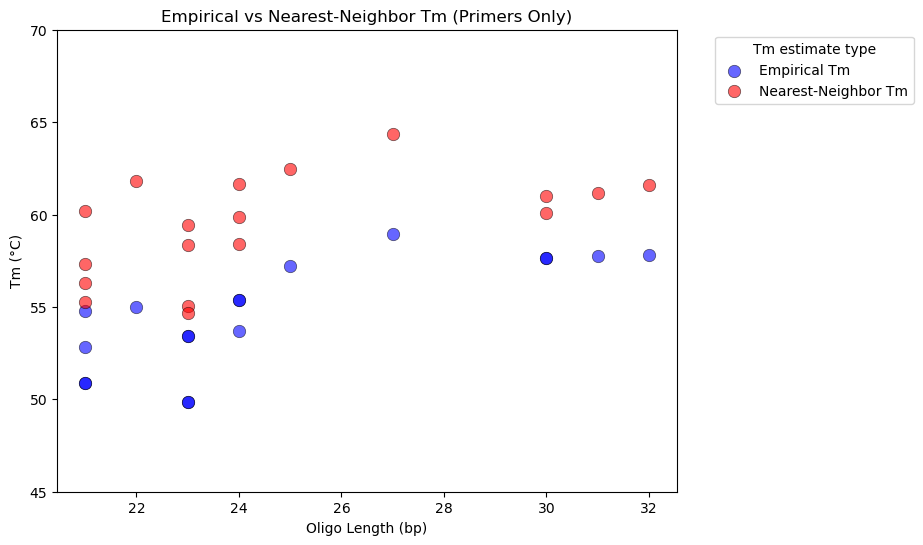

In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read the TSV file
df = pd.read_csv("oligo_results_annotated.tsv", sep="\t")

# Keep only the primers in copy of the DataFrame
df_primers = df[df["Oligo_type"] == "primer"].copy()

plt.figure(figsize=(8, 6))

# Blue scatterplot layer for Emp_Tm
sns.scatterplot(
    data=df_primers,
    x="Length",         # length on the x-axis
    y="Emp_Tm",         # Empirical Tm estimates on the y-axis
    color="blue",
    alpha=0.6,
    label="Empirical Tm",
    s=80,               # relative marker size
    edgecolor="black",
    linewidth=0.5,
    legend=False
)

# Red scatterplot layer for NN_Tm
sns.scatterplot(
    data=df_primers,
    x="Length",         # length on the x-axis
    y="NN_Tm",          # Nearest-Neighbor Tm on the y-axis
    color="red",
    alpha=0.6,
    label="Nearest-Neighbor Tm",
    s=80,
    edgecolor="black",
    linewidth=0.5,
    legend=False
)

# Legend for the two Tm types
plt.legend(title="Tm estimate type", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xlabel("Oligo Length (bp)")
plt.ylabel("Tm (°C)")
plt.ylim(45, 70)
plt.title("Empirical vs Nearest-Neighbor Tm (Primers Only)")
plt.show()

In [60]:
df_primers

,Name,Sequence,Length,GC_perc,Emp_Tm,NN_Tm,Oligo_type
0,dcl1_geno_F1,TAATGCGGGAGAGGATCAAGG,21,52.4,52.81,57.33,primer
1,dcl1_geno_R1,AGTAGAAGAACCGCAGCTGAATC,23,47.8,53.42,58.36,primer
2,dcl2_geno_F2,AACCCAAAGGTTGGATGGTTCCAGG,25,52.0,57.22,62.48,primer
3,dcl2_geno_R2,AAGATATATCGGATTCCCATCCGAAAGTGG,30,43.3,57.67,61.01,primer
4,dcl3-1_geno_F1,TGTCTATCGACTACAGAGAGATTTTGCATTGC,32,40.6,57.81,61.61,primer
5,dcl3-1_geno_R1,TGCGGCAAATACACCCCAATGG,22,54.5,54.99,61.83,primer
6,dcl3-2_geno_F1,GTCAGAGATCACTAAGAGGCTTATCAAAGC,30,43.3,57.67,60.10,primer
7,dcl3-2_geno_F1,TAGTTTCAGGAATGCACTTCTAAGGACATCC,31,41.9,57.74,61.17,primer
8,dcl4_geno_F1,GGCTGCACAGCTGATGATTACAA,23,47.8,53.42,59.41,primer
9,dcl4_geno_R1,GCCGCTCGAGATCATCAGCAAAGGAAT,27,51.9,58.94,64.38,primer


In [61]:
# Convert DataFrame from "wide" to "long" format
df_long = df_primers.melt(
    id_vars=["Name", "Length", "GC_perc", "Oligo_type"],
    value_vars=["Emp_Tm", "NN_Tm"],   # columns to reshape
    var_name="Tm_type",               # new column name
    value_name="Tm"                   # single numeric column
)
df_long

,Name,Length,GC_perc,Oligo_type,Tm_type,Tm
0,dcl1_geno_F1,21,52.4,primer,Emp_Tm,52.81
1,dcl1_geno_R1,23,47.8,primer,Emp_Tm,53.42
2,dcl2_geno_F2,25,52.0,primer,Emp_Tm,57.22
3,dcl2_geno_R2,30,43.3,primer,Emp_Tm,57.67
4,dcl3-1_geno_F1,32,40.6,primer,Emp_Tm,57.81
5,dcl3-1_geno_R1,22,54.5,primer,Emp_Tm,54.99
6,dcl3-2_geno_F1,30,43.3,primer,Emp_Tm,57.67
7,dcl3-2_geno_F1,31,41.9,primer,Emp_Tm,57.74
8,dcl4_geno_F1,23,47.8,primer,Emp_Tm,53.42
9,dcl4_geno_R1,27,51.9,primer,Emp_Tm,58.94


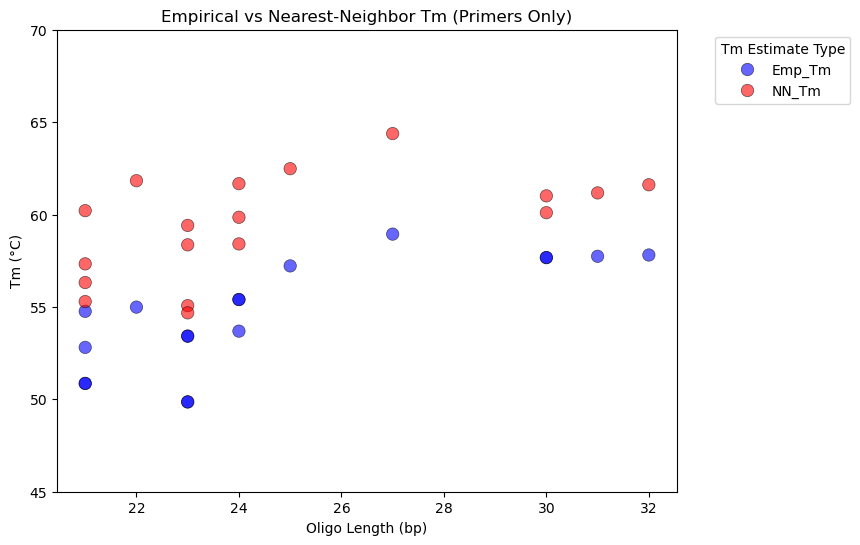

In [62]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Single sns.scatterplot() call because Emp_Tm and NN_Tm data are in "long" format
sns.scatterplot(
    data=df_long,
    x="Length",           # length on x-axis
    y="Tm",               # Tm estimates on y-axis (Emp_Tm and NN_Tm)
    hue="Tm_type",        # color-coded by method
    palette={"Emp_Tm": "blue", "NN_Tm": "red"},
    alpha=0.6,
    s=80,
    edgecolor="black",
    linewidth=0.5
)

plt.xlabel("Oligo Length (bp)")
plt.ylabel("Tm (°C)")
plt.ylim(45, 70)
plt.title("Empirical vs Nearest-Neighbor Tm (Primers Only)")
plt.legend(
    title="Tm Estimate Type",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.show()

In [63]:
pd.set_option("display.max_rows", None)

# Read the TSV file
df = pd.read_csv("oligo_results_annotated.tsv", sep="\t")

# Convert entire DataFrame into "long" format (keeping primers and controls) 
df_long = df.melt(
    id_vars=["Name", "Length", "GC_perc", "Oligo_type"],
    value_vars=["Emp_Tm", "NN_Tm"],   # columns to reshape
    var_name="Tm_type",               # new column name
    value_name="Tm"                   # single numeric column
)
df_long

,Name,Length,GC_perc,Oligo_type,Tm_type,Tm
0,dcl1_geno_F1,21,52.4,primer,Emp_Tm,52.81
1,dcl1_geno_R1,23,47.8,primer,Emp_Tm,53.42
2,dcl2_geno_F2,25,52.0,primer,Emp_Tm,57.22
3,dcl2_geno_R2,30,43.3,primer,Emp_Tm,57.67
4,dcl3-1_geno_F1,32,40.6,primer,Emp_Tm,57.81
5,dcl3-1_geno_R1,22,54.5,primer,Emp_Tm,54.99
6,dcl3-2_geno_F1,30,43.3,primer,Emp_Tm,57.67
7,dcl3-2_geno_F1,31,41.9,primer,Emp_Tm,57.74
8,dcl4_geno_F1,23,47.8,primer,Emp_Tm,53.42
9,dcl4_geno_R1,27,51.9,primer,Emp_Tm,58.94


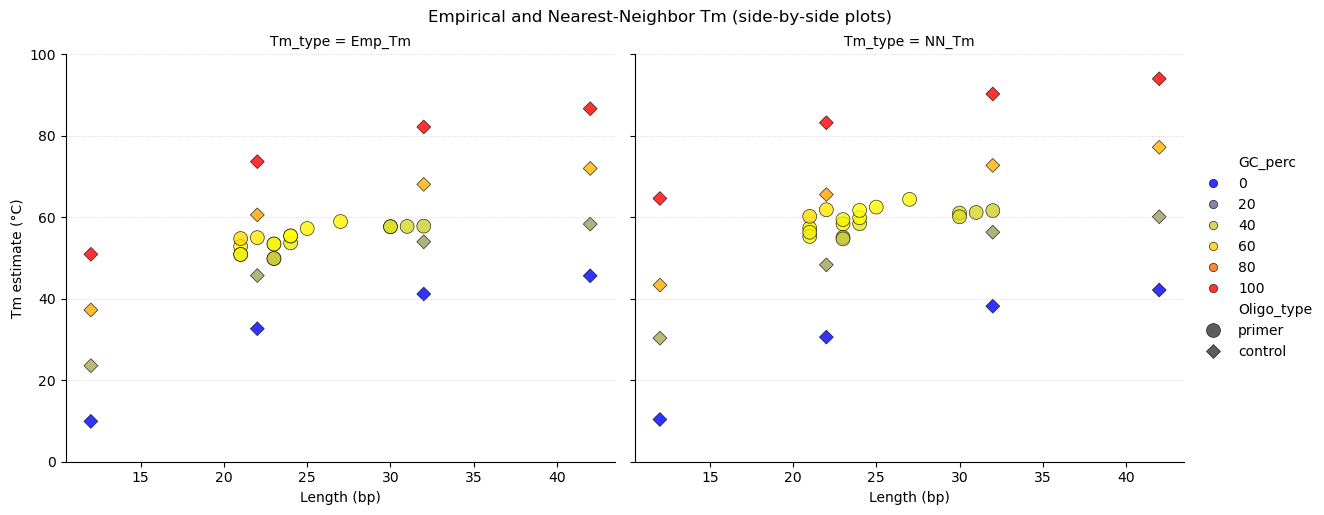

In [64]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Custom color gradient from blue to red
colors = ['blue', 'yellow', 'red']
custom_cmap = LinearSegmentedColormap.from_list('custom', colors)

# Relational plots with facets (returns a FacetGrid object (g))
g = sns.relplot(
    data=df_long,
    kind="scatter",
    x="Length",
    y="Tm",
    hue="GC_perc",
    col="Tm_type",              # one column for Emp_Tm, one for NN_Tm
    palette=custom_cmap,
    alpha=0.8,
    style="Oligo_type",
    markers={"primer": "o", "control": "D"},
    size="Oligo_type",
    sizes={"primer": 100, "control": 50},
    edgecolor="black",
    linewidth=0.5,
    height=5,
    aspect=1.2,
)

g.set_axis_labels("Length (bp)", "Tm estimate (°C)")
g.set(ylim=(0, 100))
g.figure.suptitle("Empirical and Nearest-Neighbor Tm (side-by-side plots)", y=1.02)

# Add horizontal dotted lines at y-ticks
for ax in g.axes.flat:
    ax.grid(axis='y', linestyle=':', linewidth=0.6, alpha=0.6)
    
plt.show()

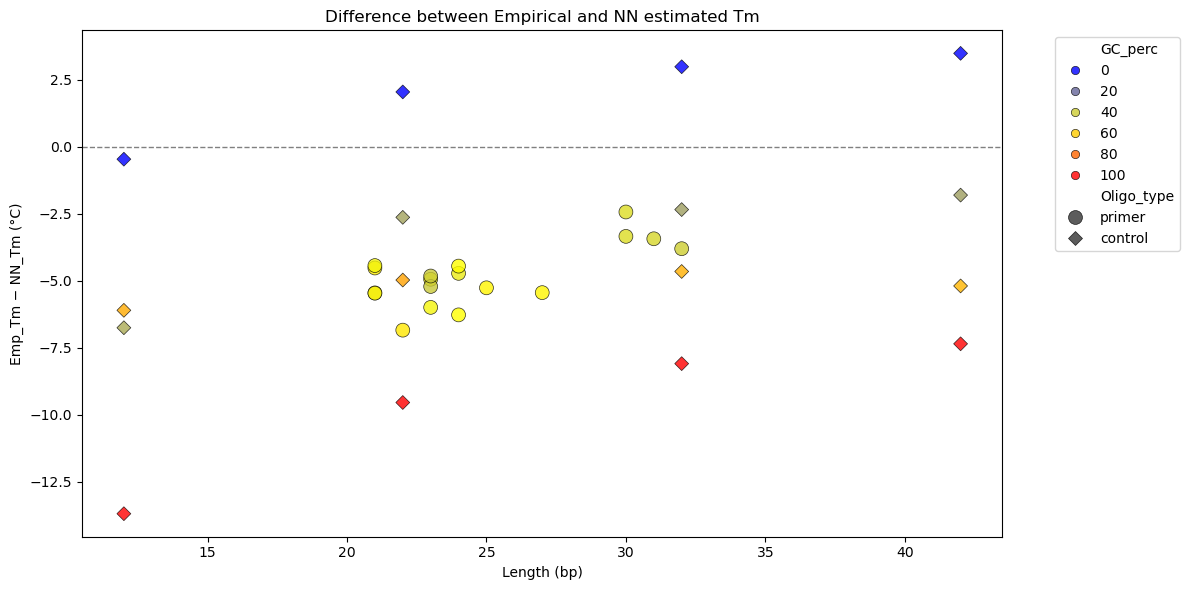

In [65]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Read the TSV file, keeping the wide format here
df = pd.read_csv('oligo_results_annotated.tsv', sep='\t')

# Compute difference between empirical and NN Tm
df["Tm_diff"] = df["Emp_Tm"] - df["NN_Tm"]

# Custom color gradient from blue to red
colors = ['blue', 'yellow', 'red']
custom_cmap = LinearSegmentedColormap.from_list('custom', colors)

plt.figure(figsize=(12, 6))

scatter = sns.scatterplot(
    data=df,
    x='Length',
    y='Tm_diff',    # plot Tm estimate differences (Emp_Tm − NN_Tm) on the y-axis
    hue='GC_perc',
    palette=custom_cmap,
    alpha=0.8,
	style='Oligo_type',
    markers={'primer': 'o', 'control': 'D'}, 
    size='Oligo_type',
	sizes={'primer':100, 'control':50},
    edgecolor='black',
    linewidth=0.5
    )

# Zero-line where NN_Tm == Emp_Tm
plt.axhline(0, linestyle='--', color='gray', linewidth=1)

plt.xlabel('Length (bp)')
plt.ylabel('Emp_Tm − NN_Tm (°C)')
plt.title('Difference between Empirical and NN estimated Tm')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [66]:
# New column was created "Tm_diff"
df

,Name,Sequence,Length,GC_perc,Emp_Tm,NN_Tm,Oligo_type,Tm_diff
0,dcl1_geno_F1,TAATGCGGGAGAGGATCAAGG,21,52.4,52.81,57.33,primer,-4.52
1,dcl1_geno_R1,AGTAGAAGAACCGCAGCTGAATC,23,47.8,53.42,58.36,primer,-4.94
2,dcl2_geno_F2,AACCCAAAGGTTGGATGGTTCCAGG,25,52.0,57.22,62.48,primer,-5.26
3,dcl2_geno_R2,AAGATATATCGGATTCCCATCCGAAAGTGG,30,43.3,57.67,61.01,primer,-3.34
4,dcl3-1_geno_F1,TGTCTATCGACTACAGAGAGATTTTGCATTGC,32,40.6,57.81,61.61,primer,-3.80
5,dcl3-1_geno_R1,TGCGGCAAATACACCCCAATGG,22,54.5,54.99,61.83,primer,-6.84
6,dcl3-2_geno_F1,GTCAGAGATCACTAAGAGGCTTATCAAAGC,30,43.3,57.67,60.10,primer,-2.43
7,dcl3-2_geno_F1,TAGTTTCAGGAATGCACTTCTAAGGACATCC,31,41.9,57.74,61.17,primer,-3.43
8,dcl4_geno_F1,GGCTGCACAGCTGATGATTACAA,23,47.8,53.42,59.41,primer,-5.99
9,dcl4_geno_R1,GCCGCTCGAGATCATCAGCAAAGGAAT,27,51.9,58.94,64.38,primer,-5.44


In [67]:
pd.set_option("display.max_rows", None)

# Convert DataFrame into "long" format with all numerical data in "Metric" column
df_metric = df.melt(
    id_vars=["Name", "Sequence", "Oligo_type"],
    value_vars=["Length", "GC_perc", "Emp_Tm", "NN_Tm"],
    var_name="Metric",
    value_name="Value"
)

df_metric

,Name,Sequence,Oligo_type,Metric,Value
0,dcl1_geno_F1,TAATGCGGGAGAGGATCAAGG,primer,Length,21.00
1,dcl1_geno_R1,AGTAGAAGAACCGCAGCTGAATC,primer,Length,23.00
2,dcl2_geno_F2,AACCCAAAGGTTGGATGGTTCCAGG,primer,Length,25.00
3,dcl2_geno_R2,AAGATATATCGGATTCCCATCCGAAAGTGG,primer,Length,30.00
4,dcl3-1_geno_F1,TGTCTATCGACTACAGAGAGATTTTGCATTGC,primer,Length,32.00
5,dcl3-1_geno_R1,TGCGGCAAATACACCCCAATGG,primer,Length,22.00
6,dcl3-2_geno_F1,GTCAGAGATCACTAAGAGGCTTATCAAAGC,primer,Length,30.00
7,dcl3-2_geno_F1,TAGTTTCAGGAATGCACTTCTAAGGACATCC,primer,Length,31.00
8,dcl4_geno_F1,GGCTGCACAGCTGATGATTACAA,primer,Length,23.00
9,dcl4_geno_R1,GCCGCTCGAGATCATCAGCAAAGGAAT,primer,Length,27.00


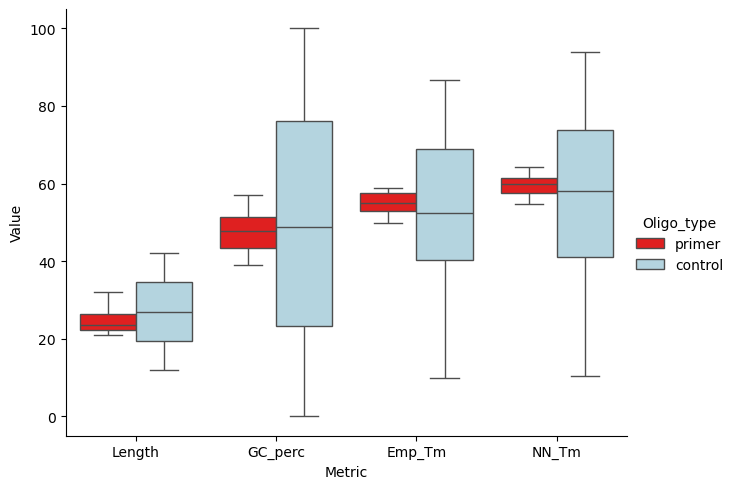

In [68]:
# Example of boxplots across all the "Metric" categories

my_palette = {
    "primer":  "red",
    "control": "lightblue"
}

sns.catplot(
    data=df_metric,
    x="Metric",
    y="Value",
    hue="Oligo_type",
    kind="box",
    palette=my_palette,
    height=5, aspect=1.3
)
plt.show()

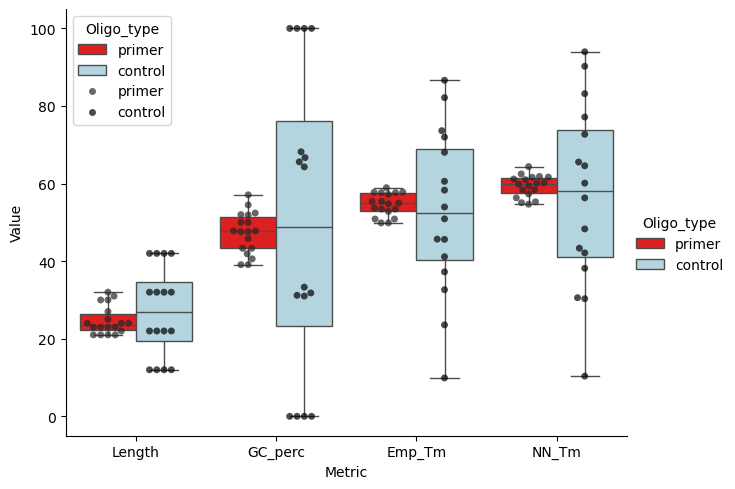

In [69]:
# Combined box and swarm plots across all the "Metric" categories
sns.catplot(
    data=df_metric,
    x="Metric",
    y="Value",
    hue="Oligo_type",
    kind="box",
    palette=my_palette,
    height=5, aspect=1.3
)

sns.swarmplot(
    data=df_metric,
    x="Metric",
    y="Value",
    hue="Oligo_type",
    palette="dark:black",
    dodge=True,
    alpha=0.7
)
plt.show()